# Example 1: a first model

A ring of dust between 50 and 100 au around a Sun-like star at 20 pc, seen at 60° inclination:
its SED from 1 to 2000 µm and images in scattered light (1.6 µm) and thermal emission (870 µm).
About ten seconds. Start with `0_getting_started.ipynb` if DMS is not set up yet.

In [1]:
# Setup: this notebook lives in the examples/ folder of the repository
import os, sys
REPO = os.environ.get("DMS_REPO") or os.path.abspath("..")
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__, "from", os.path.relpath(os.path.dirname(dms.__file__), REPO))

DMS 2.0.0 from python/dms


## The system

Names and units are those of the input files (au, degrees, M☉, micron; `docs/input_reference.md`).
Everything that is not given keeps its default; for example the grain radii are divided into
`n_sizes = 100` logarithmic bins.

In [2]:
model = dms.Model(
    star={"teff": 5800, "radius": 1.0, "mass": 1.0, "distance": 20},     # K, R_sun, M_sun, pc
    disk={"r_in": 50, "r_out": 100,                                       # ring from 50 to 100 au
          "dust_mass": 1e-8,                                              # M_sun
          "inclination": 60, "position_angle": 30},                       # degrees
    dust={"n_components": 1, "optical_data": "astrosilicate_draine03_862",  # astronomical silicate
          "bulk_density": 3.5,                                            # g/cm^3
          "a_min": 1, "a_max": 1000, "q": 3.5},                           # radii [micron], n(a) ~ a^-q
)

## SED

`mode = "sed"` integrates the emission directly (no images), here at 60 wavelengths.

In [3]:
sed = model.copy().update(run={"mode": "sed"},
                          wavelengths={"lambda_min": 1, "lambda_max": 2000, "n_lambda": 60}).run()
print(f"fractional luminosity f_d = {sed.f_d:.2e}")
i = sed.sed["thermal"].argmax()
print(f"thermal emission peaks at {sed.wavelength[i]:.0f} micron with {sed.sed['thermal'][i]:.3f} Jy")

fractional luminosity f_d = 8.09e-05
thermal emission peaks at 80 micron with 0.089 Jy


## Images

Scattered light at 1.6 µm and thermal emission at 870 µm, 151 × 151 pixels. `img.image(name)` returns
a cube `[wavelength, y, x]` in Jy per pixel.

In [4]:
img = model.copy().update(run={"mode": "image"}, wavelengths={"lambda": [1.6, 870]},
                          image={"n_pixels": 151}).run()
print(f"{img.image('total').shape[1]} x {img.image('total').shape[2]} pixels "
      f"of {img.pixel_au:.2f} au ({img.pixel_arcsec:.3f} arcsec); images: {', '.join(img.images)}")

151 x 151 pixels of 1.32 au (0.066 arcsec); images: reem, sca, q, u, pol, qphi, uphi, poldeg, total


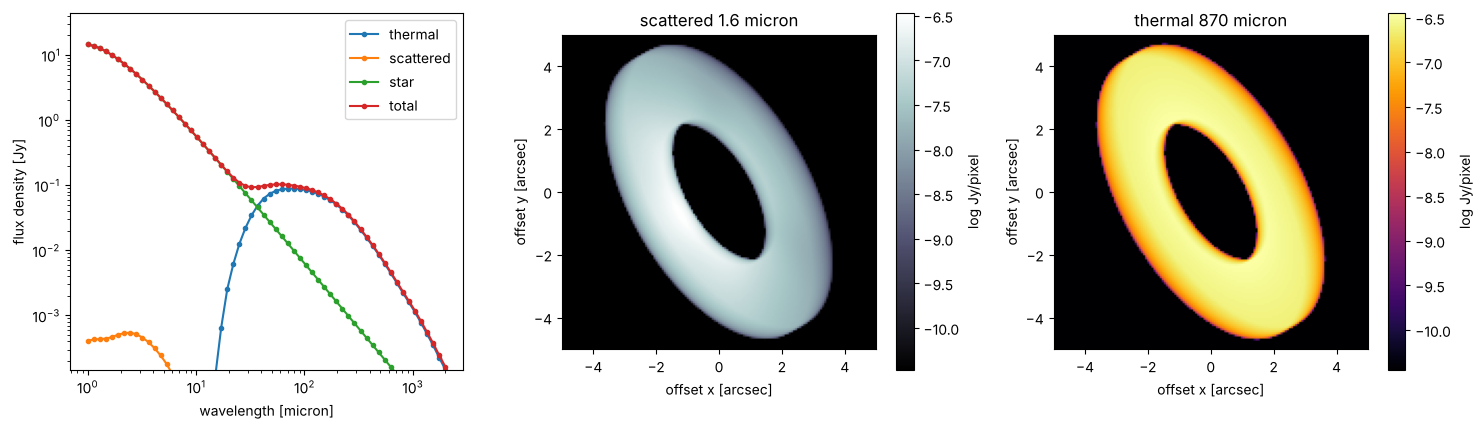

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
dms.plot.sed(sed, ax=ax[0])
top = sed.sed["total"].max()
ax[0].set_ylim(1e-5 * top, 3 * top)       # the thermal SED falls steeply below ~10 micron
dms.plot.image(img, "scattered", il=0, ax=ax[1], cmap="bone")
dms.plot.image(img, "thermal", il=1, ax=ax[2])
fig.tight_layout()
plt.show()

## Changing the model

`update` changes parameters in place; run the model again to see the effect. Here the ring becomes
eccentric (e = 0.2, pericentre 45° from the line of nodes): the side closer to the star is warmer
and brighter at 870 µm.

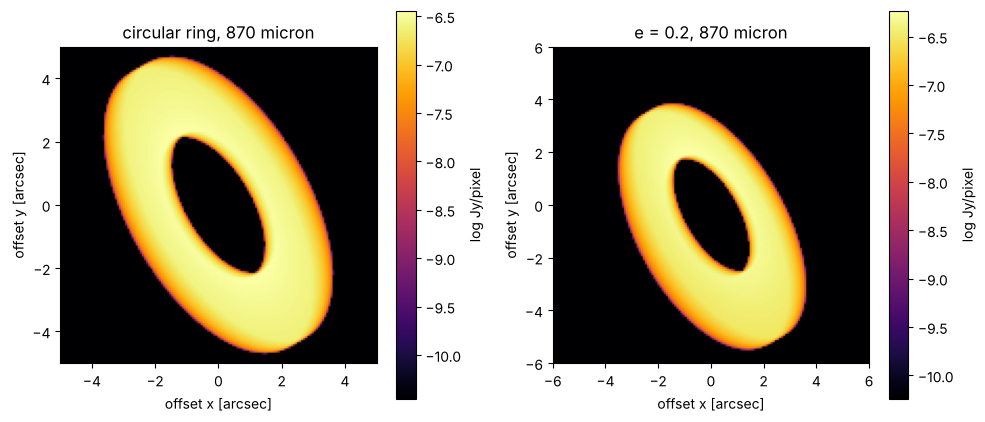

In [6]:
ecc = model.copy().update(run={"mode": "image"}, wavelengths={"lambda": [870]},
                          image={"n_pixels": 151}, disk={"eccentricity": 0.2, "omega": 45}).run()
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
dms.plot.image(img, "thermal", il=1, ax=ax[0])
ax[0].set_title("circular ring, 870 micron")
dms.plot.image(ecc, "thermal", ax=ax[1])
ax[1].set_title("e = 0.2, 870 micron")
fig.tight_layout()
plt.show()